## Signals and interpolation

A sampled signal in time and in frequency: the fast Fourier transform, two simple filters, and ways to fill in values between samples.

### The spectrum of a noisy signal

Two sines, at 50 Hz and 120 Hz, buried in noise stronger than they are. The FFT's magnitude shows the two frequencies plainly. With $N$ samples at rate $F_s$, bin $k$ is the frequency $k F_s / N$.

signal-to-noise: the noise's rms is 1.51, the clean signal's 0.86



found =

    50   120



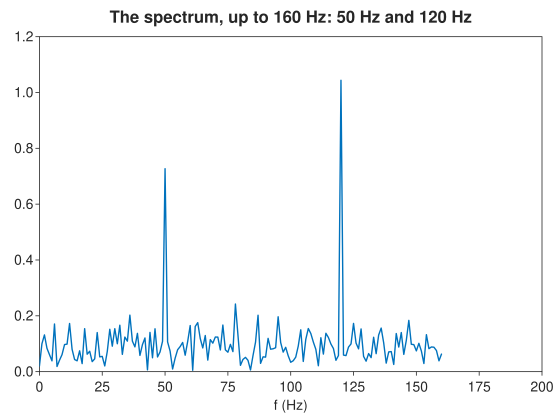

In [ ]:
figure
rng(4);
rms = @(e) sqrt(mean(e.^2));
Fs = 1000; N = 1000;
t = (0:N-1) / Fs;
clean = 0.7*sin(2*pi*50*t) + sin(2*pi*120*t);
noisy = clean + 1.5*randn(size(t));
Y = fft(noisy);
amp = abs(Y(1:N/2+1)) / N;
amp(2:end-1) = 2*amp(2:end-1);
freqs = Fs * (0:N/2) / N;
plot(freqs(1:161), amp(1:161)), xlabel('f (Hz)'), title('The spectrum, up to 160 Hz: 50 Hz and 120 Hz')
fprintf('signal-to-noise: the noise''s rms is %.2f, the clean signal''s %.2f\n', rms(noisy - clean), rms(clean))
[~, order] = sort(amp, 'descend');
top = order(1:2);
found = sort(freqs(top))

### Two filters

A moving average is a convolution with a short box (`conv`); `filter` applies a recursive filter, here exponential smoothing $y_k = \alpha x_k + (1 - \alpha) y_{k-1}$. Both remove much of the noise, and blunt the 120 Hz tone a little too.

In [ ]:
box = ones(1, 15) / 15;
averaged = conv(noisy, box, 'same');
alpha = 0.1;
smoothed = filter(alpha, [1, alpha - 1], noisy);
fprintf('distance from the clean signal (rms): noisy %.3f, moving average %.3f, exponential %.3f\n', ...
    rms(noisy - clean), rms(averaged - clean), rms(smoothed - clean))

distance from the clean signal (rms): noisy 1.506, moving average 0.938, exponential 0.874


### Interpolation

Nine samples of a smooth function, filled in three ways. `'linear'` joins the dots, `'pchip'` keeps the data's shape without overshoot, and `'spline'` is the smoothest.


spline_error =

    0.0242



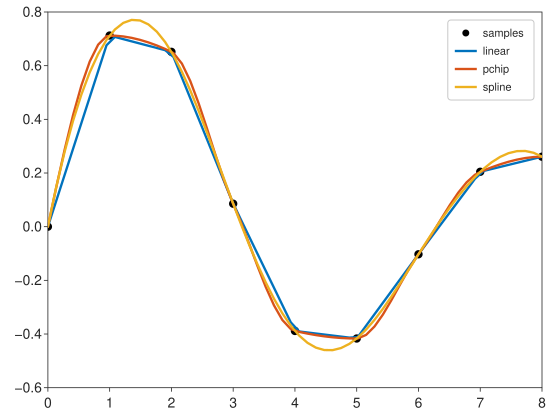

In [ ]:
figure
xk = 0:8;
yk = sin(xk) .* exp(-xk/6);
xq = linspace(0, 8, 60);
plot(xk, yk, 'ko', xq, interp1(xk, yk, xq, 'linear'), xq, interp1(xk, yk, xq, 'pchip'), xq, spline(xk, yk, xq), 'LineWidth', 1.2)
legend('samples', 'linear', 'pchip', 'spline')
spline_error = max(abs(spline(xk, yk, xq) - sin(xq).*exp(-xq/6)))

*Topics after examples in MatRust-Studio (MIT license); the code here is Sagebrush's own.*